# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [5]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [6]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

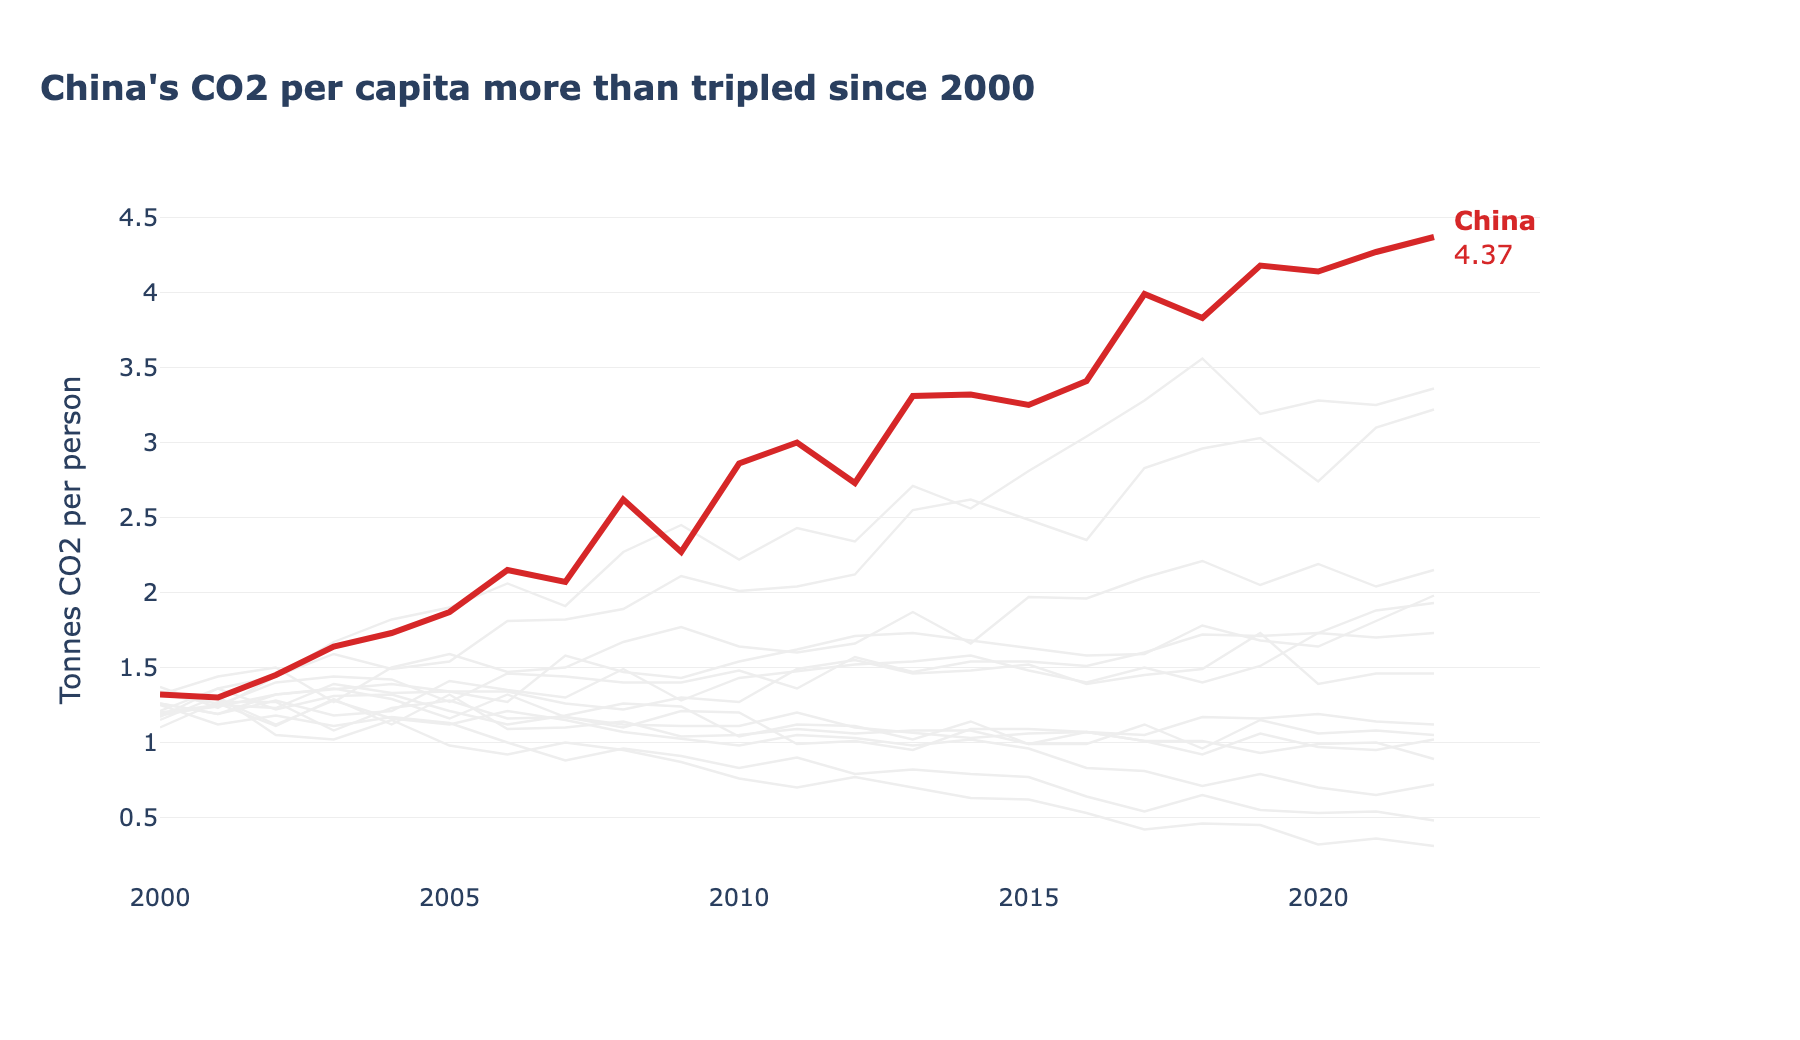

In [9]:
# Task 1 — CO2 per capita, all countries, China highlighted
highlight = 'China'

# Put the highlighted country's rows last (order inside each country unchanged) so its line is drawn on top of the grey ones
data = pd.concat([df[df['Country'] != highlight], df[df['Country'] == highlight]])
colors = {c: '#EEEEEE' for c in data['Country']}
colors[highlight] = '#D62728'

fig = px.line(data, x='Year', y='CO2_per_capita', color='Country',
              color_discrete_map=colors,
              labels={'CO2_per_capita': 'Tonnes CO2 per person', 'Year': ''},
              title="<b>China's CO2 per capita more than tripled since 2000</b>",
              template='plotly_white', width=900, height=520)

fig.update_traces(line_width=1.2, showlegend=False)                # thin grey context lines, no legend
fig.update_traces(line_width=3, selector=dict(name=highlight))     # thick highlighted line

# Direct label at the end of the highlighted line
end = data[(data['Country'] == highlight) & (data['Year'] == 2022)].iloc[0]
fig.add_annotation(x=2022, y=end['CO2_per_capita'], text=f"<b>{highlight}</b><br>{end['CO2_per_capita']}",
                   showarrow=False, xanchor='left', xshift=8, align='left',
                   font=dict(color='#D62728', size=13))

fig.update_layout(title_x=0, margin=dict(r=130),title_pad_l=20,
                  xaxis_showgrid=False, yaxis_gridcolor='#EEEEEE', yaxis_gridwidth=0.5)
fig.show(renderer='png', scale=2)   # static image, so the chart also shows on GitHub


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

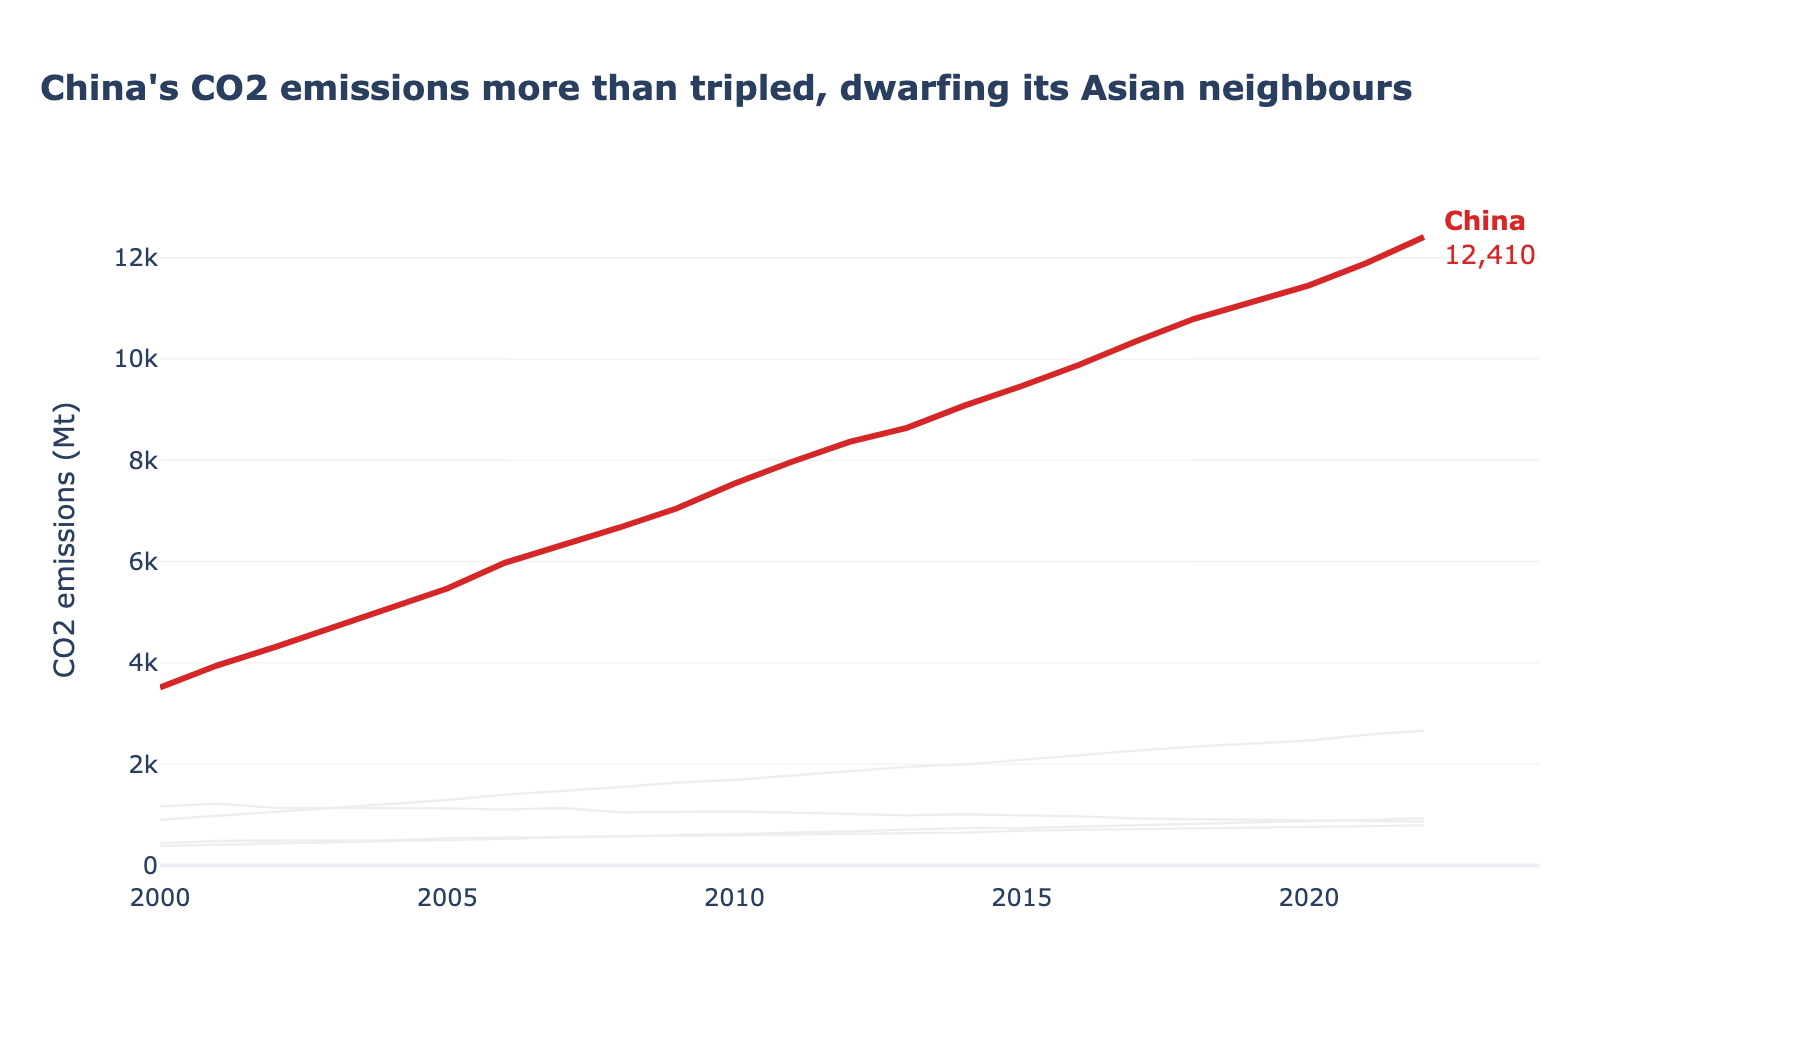

In [10]:
# Task 2 — CO2 emissions, Asian countries, China highlighted
highlight = 'China'

asia = df[df['Region'] == 'Asia']
asia = pd.concat([asia[asia['Country'] != highlight], asia[asia['Country'] == highlight]])
colors = {c: '#EEEEEE' for c in asia['Country']}
colors[highlight] = '#D62728'

fig = px.line(asia, x='Year', y='CO2_Mt', color='Country',
              color_discrete_map=colors,
              labels={'CO2_Mt': 'CO2 emissions (Mt)', 'Year': ''},
              title="<b>China's CO2 emissions more than tripled, dwarfing its Asian neighbours</b>",
              template='plotly_white', width=900, height=520)

fig.update_traces(line_width=1.2, showlegend=False)
fig.update_traces(line_width=3, selector=dict(name=highlight))

end = asia[(asia['Country'] == highlight) & (asia['Year'] == 2022)].iloc[0]
fig.add_annotation(x=2022, y=end['CO2_Mt'], text=f"<b>{highlight}</b><br>{end['CO2_Mt']:,.0f}",
                   showarrow=False, xanchor='left', xshift=8, align='left',
                   font=dict(color='#D62728', size=13))

fig.update_layout(title_x=0, margin=dict(r=130),title_pad_l=20,
                  xaxis_showgrid=False, yaxis_gridcolor='#EEEEEE', yaxis_gridwidth=0.5)
fig.show(renderer='png', scale=2)   # static image, so the chart also shows on GitHub
